В цьому домашньому завданні відпрацюємо з вами знання, отримані в модулі зі статистики.

**Завдання 1.** Ми обговорили з Вами на лекції, що велика літера Сігма грецького алфавіту позначає в математиці суму. Знайдіть з використанням Python $\Sigma x$, $\Sigma x^2$, та $\Sigma (x-1)^2$ для наступного набору даних:
`1 3 4`
Виведіть результат кожного обчислення на екран.

In [11]:
x = [1, 3, 4]

print(sum(x))

print(sum(i ** 2 for i in x))

print(sum((i-1) ** 2 for i in x ))

8
26
13


,*Завдання 2.** Ми зібрали дані про суму покупок в гривнях 20ма випадково обраними клієнтами в нашому магазині (всього клієнтів у нас більше) за минулий місяць. Вони представлені в змінній `sum_purchases`. Знайдіть **вибіркове середнє** для цих даних кожним з зазначених методів:   

  2.1. без використання жодних бібліотек, користуючись тільки Python.  
  2.2. використовуючи відповідний метод бібліотеки `numpy`.

  Виведіть результат обчислень в кожному з випадків на екран та порівняйте результати. Вони співпадають?

In [1]:
sum_purchases = [ 316,  493,  367,  153,  224,  121,  322,  450,  196,  397,  281,
  239,  484,  124,  223,  448,  432,  255, 4310, 3524]

In [11]:
import numpy as np

mean_s = sum(sum_purchases) / len(sum_purchases)

print(mean_s)

np.mean(sum_purchases)

667.95


np.float64(667.95)

**Завдання 3.** Для того ж набору даних в змінній `sum_purchases` обчисліть **медіану** кожним з зазначених методів:  

  3.1. без використання жодних бібліотек, користуючись тільки Python.  
  3.2. використовуючи відповідний метод бібліотеки numpy.  

Виведіть результат обчислень в кожному з випадків на екран. Порівняйте результати зі значенням вибіркового середнього. Напишіть коментар, для яких задач ви б використовували вибіркове середнє, а для яких - медіану?

In [10]:
#Метод Python
print((sorted(sum_purchases)[len(sum_purchases)//2-1] + sorted(sum_purchases)[len(sum_purchases)//2]) / 2)

#Метод numpy
print(np.median(sum_purchases))


319.0
319.0


**Завдання 4**. Обчислість стандартне відхилення наведеної вибірки в змінній `sum_purchases` кожним з зазначених методів:  

  4.1. без використання жодних бібліотек, користуючись тільки Python.  
  4.2. використовуючи відповідний метод бібліотеки numpy.  

Виведіть результат обчислень в кожному з випадків на екран.

In [13]:
#Метод numpy
print(np.std(sum_purchases, ddof=1))


#Метод Python
std_s = (sum((el - mean_s)**2 for el in sum_purchases) / (len(sum_purchases)-1))**0.5
print(std_s)

1124.5433447451132
1124.5433447451132


**Завдання 5**. Ми провели дослідження віку студентів-першокурсників. Виявилось, що
- 10 студентів мають вік 16 років
- 25 студентів - 17 років
- 20 студентів - 18 років
- 2 студенти - 20 років

Обчислість середнє значення для цієї вибірки будь-яким способом - на чистому Python або з numpy - та виведіть результат на екран.

In [8]:
student = [16] * 10 + [17] * 25 + [18] * 20 + [20] * 2

print(np.mean(student))

17.280701754385966


**Завдання 6**. Крім даних про суму покупок, ми зібрали ще дані про кількість відвідувань кожного з кожного покупця, які знаходяться в змінній `visits`. Обчисліть коефіцієнт кореляції Пірсона для суми покупок і кількості відвідувань кожним з зазначених методів:  

  6.1. без використання жодних бібліотек, користуючись тільки Python.  
  6.2. використовуючи відповідний метод бібліотеки numpy.  
  
Виведіть результат на екран. Проаналізуйте результат.

Виведіть додатково графік розсіювання викликавши код нижче і зробіть заключення, чи варто щось змінити при підрахунку кореляції, аби коефіцієнт Пірсона показував коректну оцінку лінійної залежності?

In [6]:
visits = [ 6,  2, 10,  3,  9,  9,  2,  3,  6,  6, 10,  2,  5, 10,  3,  5,  4,
        7,  4,  2]

In [22]:
#Метод Python
mean_v = sum(visits) / len(visits)

cov = sum((sum_purchases[i] - mean_s) * (visits[i] - mean_v) for i in range(len(sum_purchases))) / (len(sum_purchases)-1)

std_v = (sum((el - mean_v) ** 2 for el in visits) / (len(visits)-1)) ** 0.5

pearson_python = cov / (std_s * std_v)

print(pearson_python)

#Метод numpy
print(np.corrcoef(sum_purchases, visits)[0,1])

# негативна кореляція, але через 2 викиди кореляція, може бути некоректною

-0.30265844687666454
-0.3026584468766646


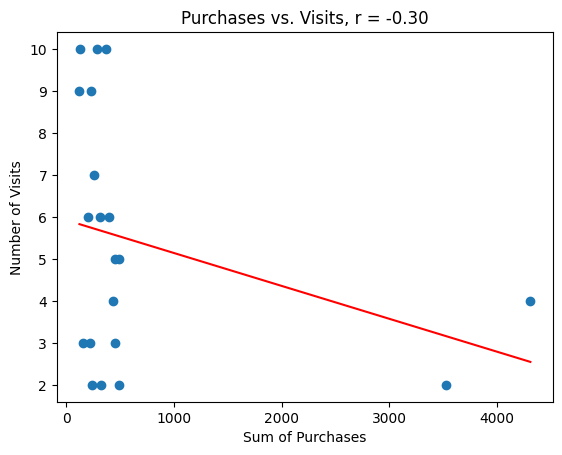

In [23]:
import matplotlib.pyplot as plt
k, b = np.polyfit(sum_purchases, visits, 1)
xs = np.array([min(sum_purchases), max(sum_purchases)])

plt.scatter(sum_purchases, visits)
plt.plot(xs, k * xs + b, color='red')
plt.title(f'Purchases vs. Visits, r = {pearson_python:.2f}')
plt.xlabel('Sum of Purchases')
plt.ylabel('Number of Visits');

**Завдання 7**. В попередньому завданні ми помітили, що викиди нам заважають отримати "правдиве" значення кореляції. Давайте вилучимо записи, які відповідають значенням з викидами в сумі покупок і обчисліть коеф. кореляції. Для цього поставте `threshold`, який дорінює середньому значенню + 2 стандартних вдіхилля суми покупок і всі значення, які більше за нього, будемо вважати викидами (є і інші правила для визначення викидів - з ним и познайомимось пізніше).

Вилучіть значення з обох масивів і обчисліть коеф. кореляції Пірсона з допомогою `numpy` для кількості візитів і суми покупок без записів-викидів. Виведіть результат на екран, побудуйте діаграму розсіювання і проаналізуйте результат: що можемо сказати про залежність в даних?

In [24]:
threshold = mean_s + 2 * std_s

pairs = [(p, v) for p, v in zip(sum_purchases, visits) if p <= threshold]
purchases_clean = [p for p, v in pairs]
visits_clean = [v for p, v in pairs]

pearson_clean = np.corrcoef(purchases_clean, visits_clean)[0, 1]
print(pearson_clean)

#Негативна кореляція, але результат суттєво не помінявся

-0.3685212078127798


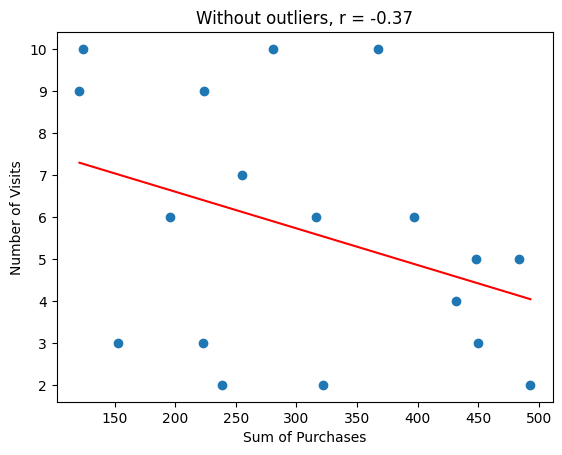

In [25]:
k, b = np.polyfit(purchases_clean, visits_clean, 1)
xs = np.array([min(purchases_clean), max(purchases_clean)])

plt.scatter(purchases_clean, visits_clean)
plt.plot(xs, k * xs + b, color='red')
plt.title(f'Without outliers, r = {pearson_clean:.2f}')
plt.xlabel('Sum of Purchases')
plt.ylabel('Number of Visits');